In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np

In [3]:
data = pd.read_csv('../misc_data/SpermNanodrop_tidy.csv')
data

,fishID,condition,collection number,Collection,nanodrop,diluted to,uL used,ng used
0,1,edited,1,1.1,338.1,NaN,NaN,NaN
1,1,edited,2,1.2,204.9,NaN,NaN,NaN
2,1,edited,3,1.3,360.9,NaN,NaN,NaN
3,1,edited,4,1.4,315.1,NaN,NaN,NaN
4,1,edited,5,1.5,368.8,NaN,1.5,553.2
...,...,...,...,...,...,...,...,...
473,NaN,NaN,14,water,9.4,NaN,1,9.4
474,NaN,NaN,8,water,0.3,NaN,1,0.3
475,NaN,NaN,14,water,2.5,NaN,1,2.5
476,NaN,NaN,14,water,2.3,NaN,1,2.3


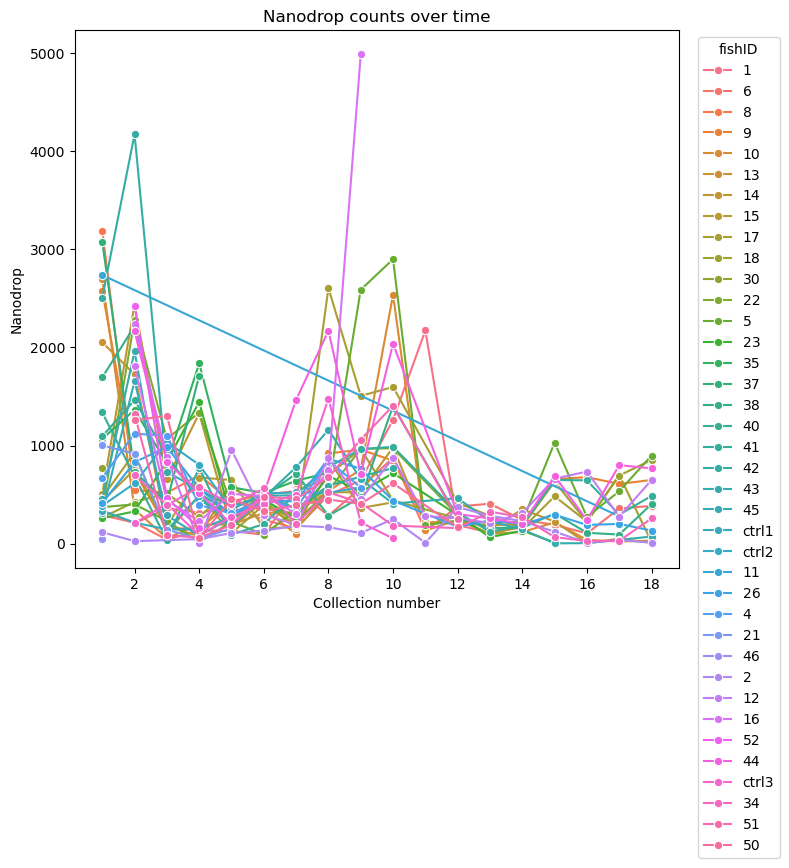

In [23]:
plot_data = data[['collection number', 'nanodrop', 'fishID']].copy()
for column in ['collection number', 'nanodrop']:
    plot_data[column] = pd.to_numeric(plot_data[column], errors='coerce')
plot_data = plot_data.dropna().sort_values('collection number')
plot_data['fishID'] = plot_data['fishID'].astype(str)

fig, ax = plt.subplots(figsize=(8, 8))
sb.lineplot(
    data=plot_data, x='collection number', y='nanodrop', hue='fishID',
    marker='o', estimator=None, ax=ax,
)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_xlabel('Collection number')
ax.set_ylabel('Nanodrop')
ax.set_title('Nanodrop counts over time')
ax.legend(title='fishID', bbox_to_anchor=(1.02, 1), loc='upper left')
#plt.gca().get_legend().remove()
fig.tight_layout()
plt.show()